In [1]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
import scipy.linalg as la
import itertools
from tqdm.auto import tqdm
import time

In [2]:
import mctpy as mct

In [3]:
def finger (kappa0, gammadot, t):
    gt = gammadot*t
    F = la.expm(kappa0*gt)
    return np.dot(F,F.T)
def dB (kappa0, gammadot, t):
    B = finger(kappa0, gammadot, t)
    return (kappa0 @ B + B @ kappa0.T) * gammadot
def dBinv (kappa0, gammadot, t):
    Binv = la.inv(finger(kappa0, gammadot, t))
    return (kappa0.T @ Binv + Binv @ kappa0) * (-gammadot)

In [4]:
kappa0 = np.array([[0,1,0],[0,0,0],[0,0,0]])

In [5]:
gammadot = 10**np.linspace(0,-9,40)
sigma_s = np.zeros((gammadot.shape[0], 3, 3))

In [6]:
t0 = time.time()
v1c, v2c = 2*(np.sqrt(2.)-1), 2.0
v1, v2 = v1c - 1e-3/(np.sqrt(2)-1), v2c
model = mct.f12gammadot_tensorial_model (v1, v2, gammadot=0., gammac=0.1,
                                         use_hhat=False, nu=1.0, kappa=kappa0)
for i,gdot in enumerate(gammadot):
    model.gammadot = gdot
    phi = mct.correlator (model = model, store = True)
    correlators = mct.CorrelatorStack([phi])
    correlators.solve_all(stop_on_zero=True)
    sigma_s[i] = scipy.integrate.trapezoid(phi.shear_modulus(lc=False), x=phi.t, axis=0)
print (f'took {time.time()-t0:.2f} seconds')

took 24.67 seconds


In [7]:
sigma_scalar = np.zeros_like(gammadot)
t0 = time.time()
v1c, v2c = 2*(np.sqrt(2.)-1), 2.0
v1, v2 = v1c - 1e-3/(np.sqrt(2)-1), v2c
model = mct.f12gammadot_model (v1, v2, gammadot=0., gammac=0.1)
for i,gdot in enumerate(gammadot):
    model.gammadot = gdot
    phi = mct.correlator (model = model, store = True)
    correlators = mct.CorrelatorStack([phi])
    correlators.solve_all(stop_on_zero=True)
    sigma_scalar[i] = scipy.integrate.trapezoid(phi.shear_modulus(), x=phi.t, axis=0)
print (f'took {time.time()-t0:.2f} seconds')

took 7.70 seconds


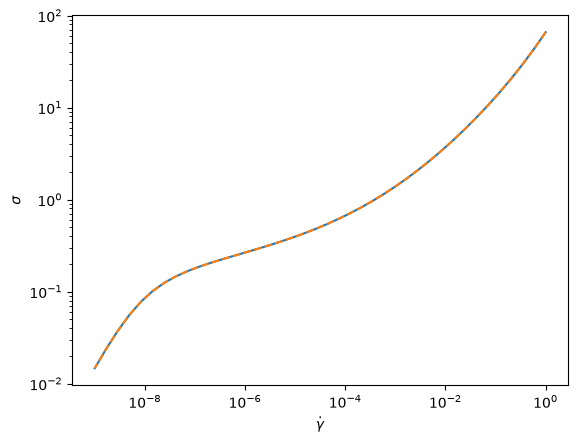

In [8]:
plt.plot(gammadot, 100*sigma_s[:,0,1])
plt.plot(gammadot, 100*sigma_scalar, linestyle='dashed')
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$\dot\gamma$')
plt.ylabel(r'$\sigma$')
plt.show()

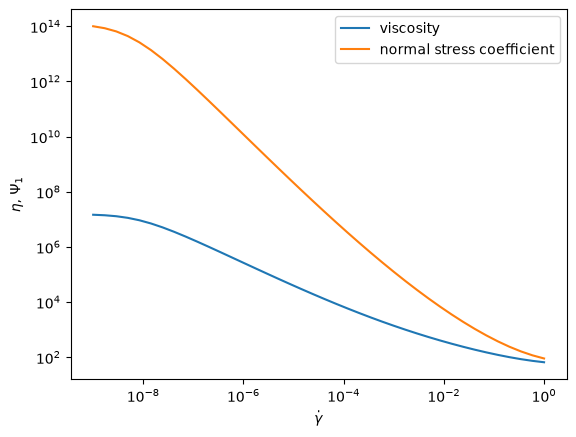

In [9]:
plt.plot(gammadot, 100*sigma_s[:,0,1]/gammadot, label='viscosity')
plt.plot(gammadot, 100*sigma_s[:,0,0]/gammadot**2, label='normal stress coefficient')
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$\dot\gamma$')
plt.ylabel(r'$\eta$, $\Psi_1$')
plt.legend()
plt.show()

In [10]:
#gammadot = 10**np.linspace(0,-9,40)
epsvals = np.sort(np.outer(10**np.linspace(-1,-4,7),[-1,1]).flatten())
sigma = np.zeros((gammadot.shape[0],epsvals.shape[0]))
tau = np.zeros_like(sigma)
tau_eq = np.zeros_like(epsvals)

In [11]:
t0 = time.time()
v1c, v2c = 2*(np.sqrt(2.)-1), 2.0
v1, v2 = v1c - 1e-3/(np.sqrt(2)-1), v2c
model = mct.f12gammadot_model (v1, v2, gammadot=0., gammac=0.1)
for j,eps in enumerate(epsvals):
    v1 = v1c - eps/(np.sqrt(2)-1)
    model.v1 = v1
    model.gammadot = 0
    phi = mct.correlator (model = model, store = True)
    correlators = mct.CorrelatorStack([phi])
    correlators.solve_all(stop_on_zero=True)
    tau_indices = phi.phi.shape[0] - np.sum(phi.phi<=0.1,axis=0)
    tau_indices[tau_indices>=phi.phi.shape[0]] = -1
    tau_eq[j] = phi.t[tau_indices][0]
print (f'took {time.time()-t0:.2f} seconds')

took 2.72 seconds


In [12]:
t0 = time.time()
v1c, v2c = 2*(np.sqrt(2.)-1), 2.0
v1, v2 = v1c - 1e-3/(np.sqrt(2)-1), v2c
model = mct.f12gammadot_model (v1, v2, gammadot=0., gammac=0.1)
for j,eps in enumerate(epsvals):
    v1 = v1c - eps/(np.sqrt(2)-1)
    model.v1 = v1
    for i,gdot in enumerate(gammadot):
        model.gammadot = gdot
        phi = mct.correlator (model = model, store = True)
        correlators = mct.CorrelatorStack([phi])
        correlators.solve_all(stop_on_zero=True)
        tau_indices = phi.phi.shape[0] - np.sum(phi.phi<=0.1,axis=0)
        tau_indices[tau_indices>=phi.phi.shape[0]] = -1
        tau[i,j] = phi.t[tau_indices][0]
        sigma[i,j] = scipy.integrate.trapezoid(phi.shear_modulus(), x=phi.t, axis=0)
print (f'took {time.time()-t0:.2f} seconds')

took 77.88 seconds


In [13]:
liq = epsvals>0

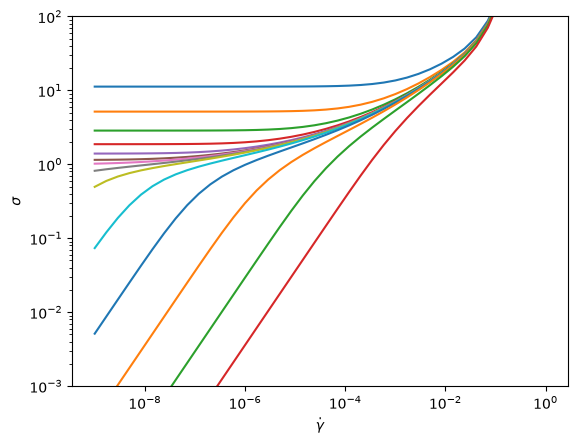

In [14]:
plt.plot(gammadot, 500*sigma*(1+100*gammadot[:,None]**2))
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$\dot\gamma$')
plt.ylabel(r'$\sigma$')
plt.ylim(0.001,100)
plt.savefig('/tmp/flowcurves.pdf',bbox_inches='tight',transparent=True)
plt.show()

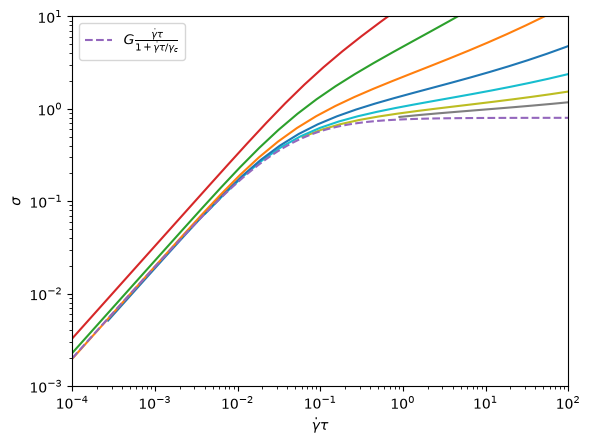

In [15]:
liq = epsvals<0
plt.plot(gammadot[:,None]*tau_eq, 500*sigma*(1+100*gammadot[:,None]**2))
gr=10**np.linspace(-4,2,100)
plt.plot(gr, 20*gr/(1+gr/0.04), linestyle='dashed',
         label=r'$G\frac{\dot\gamma\tau}{1+\dot\gamma\tau/\gamma_c}$')
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$\dot\gamma\tau$')
plt.ylabel(r'$\sigma$')
plt.xlim(0.0001,100)
plt.ylim(0.001,10)
plt.legend()
plt.savefig('/tmp/flowcurves_master.pdf',bbox_inches='tight',transparent=True)
plt.show()

In [16]:
kappa0ext = np.array([[1,0,0],[0,-1,0],[0,0,0]])
sigmaext = np.zeros((gammadot.shape[0],3,3))
sigmaext_lc = np.zeros((gammadot.shape[0],3,3))

In [17]:
v1c, v2c = 2*(np.sqrt(2.)-1), 2.0
v1, v2 = v1c - 1e-3/(np.sqrt(2)-1), v2c
model = mct.f12gammadot_tensorial_model (v1, v2, gammadot=0., gammac=0.1,
                                         use_hhat=True, nu=1.0, kappa=kappa0ext)
for i,gdot in enumerate(gammadot):
    model.gammadot = gdot
    phi = mct.correlator (model = model, store = True)
    correlators = mct.CorrelatorStack([phi])
    correlators.solve_all(stop_on_zero=True)
    sigmaext[i] = scipy.integrate.trapezoid(phi.shear_modulus(lc=False), x=phi.t, axis=0)
    sigmaext_lc[i] = scipy.integrate.trapezoid(phi.shear_modulus(lc=True), x=phi.t, axis=0)

/scratch/tv/NOSYNC/CACHE/python-mct/lib/python3.14/site-packages/mctpy/schematic.py:308: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 5474003035174155.0.
  Binv = la.inv(self.finger(t))
/scratch/tv/NOSYNC/CACHE/python-mct/lib/python3.14/site-packages/mctpy/schematic.py:308: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 7159539198064743.0.
  Binv = la.inv(self.finger(t))
/scratch/tv/NOSYNC/CACHE/python-mct/lib/python3.14/site-packages/mctpy/schematic.py:308: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 9364079851481986.0.
  Binv = la.inv(self.finger(t))
/scratch/tv/NOSYNC/CACHE/python-mct/lib/python3.14/site-packages/mctpy/schematic.py:308: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.2247435070770114e+16.
  Binv = la.inv(self.finger(t))
/scratch/tv/NOSYNC/CACHE/python-mct/lib/python3.14/site-packages/mctpy/schematic.py:308: LinAlgWarning: An ill-conditioned matrix detected: slice 0 

/scratch/tv/NOSYNC/CACHE/python-mct/lib/python3.14/site-packages/mctpy/schematic.py:308: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 4925368437910261.0.
  Binv = la.inv(self.finger(t))
/scratch/tv/NOSYNC/CACHE/python-mct/lib/python3.14/site-packages/mctpy/schematic.py:308: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 5767195270432685.0.
  Binv = la.inv(self.finger(t))
/scratch/tv/NOSYNC/CACHE/python-mct/lib/python3.14/site-packages/mctpy/schematic.py:308: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 6752904215509398.0.
  Binv = la.inv(self.finger(t))
/scratch/tv/NOSYNC/CACHE/python-mct/lib/python3.14/site-packages/mctpy/schematic.py:308: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 7907087103090809.0.
  Binv = la.inv(self.finger(t))
/scratch/tv/NOSYNC/CACHE/python-mct/lib/python3.14/site-packages/mctpy/schematic.py:308: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has 

/scratch/tv/NOSYNC/CACHE/python-mct/lib/python3.14/site-packages/mctpy/schematic.py:308: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 5117583674341040.0.
  Binv = la.inv(self.finger(t))
/scratch/tv/NOSYNC/CACHE/python-mct/lib/python3.14/site-packages/mctpy/schematic.py:308: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 6160617706077319.0.
  Binv = la.inv(self.finger(t))
/scratch/tv/NOSYNC/CACHE/python-mct/lib/python3.14/site-packages/mctpy/schematic.py:308: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 7416236438053038.0.
  Binv = la.inv(self.finger(t))
/scratch/tv/NOSYNC/CACHE/python-mct/lib/python3.14/site-packages/mctpy/schematic.py:308: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 8927767559874507.0.
  Binv = la.inv(self.finger(t))
/scratch/tv/NOSYNC/CACHE/python-mct/lib/python3.14/site-packages/mctpy/schematic.py:308: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has 

/scratch/tv/NOSYNC/CACHE/python-mct/lib/python3.14/site-packages/mctpy/schematic.py:308: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 5262106227662899.0.
  Binv = la.inv(self.finger(t))
/scratch/tv/NOSYNC/CACHE/python-mct/lib/python3.14/site-packages/mctpy/schematic.py:308: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 6544333031832427.0.
  Binv = la.inv(self.finger(t))
/scratch/tv/NOSYNC/CACHE/python-mct/lib/python3.14/site-packages/mctpy/schematic.py:308: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 8139002326936165.0.
  Binv = la.inv(self.finger(t))
/scratch/tv/NOSYNC/CACHE/python-mct/lib/python3.14/site-packages/mctpy/schematic.py:308: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.0122247531666808e+16.
  Binv = la.inv(self.finger(t))
/scratch/tv/NOSYNC/CACHE/python-mct/lib/python3.14/site-packages/mctpy/schematic.py:308: LinAlgWarning: An ill-conditioned matrix detected: slice 0 

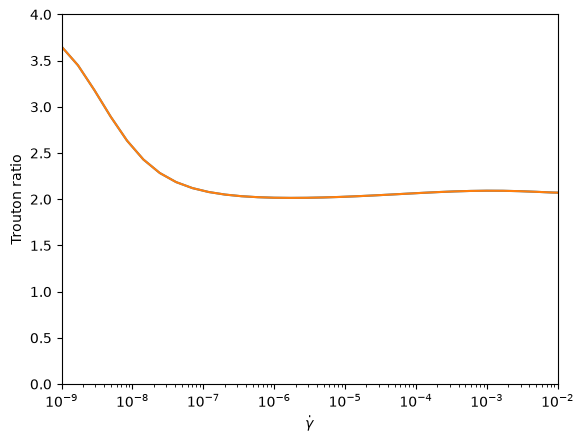

In [18]:
plt.plot(gammadot, (sigmaext[:,0,0]-sigmaext[:,1,1])/sigma_s[:,0,1])
plt.plot(gammadot, (sigmaext_lc[:,0,0]-sigmaext_lc[:,1,1])/sigma_s[:,0,1])
plt.xscale('log')
plt.xlim(1e-9,1e-2)
plt.ylim(0,4)
plt.xlabel(r'$\dot\gamma$')
plt.ylabel('Trouton ratio')
plt.show()

In [19]:
def calc_sigma(model,kappa,gammadot,lc=False):
    model.gammadot = gammadot
    model.kappa = kappa
    # here, if lc=True, should perhaps set nu=0 ?
    model.nu = float(lc == False)
    phi = mct.correlator (model=model, store=True)
    phi.solve_all(stop_on_zero=True)
    sigma = scipy.integrate.trapezoid(phi.shear_modulus(lc=lc), x=phi.t, axis=0)
    return sigma
def gen_yield_surface(model,kappagen,**kwargs):
    kappas,sigy = [],[]
    for kappa in tqdm(kappagen()):
        sigtens = calc_sigma(model,kappa,1e-9,**kwargs)
        kappas.append(kappa)
        sigy.append(sigtens)
    return np.array(kappas),np.array(sigy)

In [20]:
def kappa_pnas(A,B,C):
    return np.array([[B,C,0],[0,-(A+B)/2,0],[0,0,(A-B)/2]])
def pnas_family():
    for A in np.linspace(-1,1,9):
        yield kappa_pnas(A=A,B=1,C=0)

In [21]:
def kappadiag(ex,ey,ez):
    return np.array([[ex,0,0],[0,ey,0],[0,0,ez]])
def s_family():
    for A in np.linspace(-1,1,9):
        for B in np.linspace(-1,1,3):
            if np.isclose(A,0) and np.isclose(B,0): continue
            yield kappadiag(A,B,-(A+B))

In [22]:
v1c, v2c = 2*(np.sqrt(2.)-1), 2.0
v1, v2 = v1c + 1e-3/(np.sqrt(2)-1), v2c
model = mct.f12gammadot_tensorial_model (v1, v2, gammadot=0., gammac=0.1,
                                         use_hhat=True, nu=1.0)
kappas, sigs = gen_yield_surface(model, s_family, lc=False)

0it [00:00, ?it/s]

In [23]:
def lode_coordinates(sigma):
    s1,s2,s3 = la.eig(sigma)[0]
    x = (s2.real-s1.real)/np.sqrt(2.)
    y = (2*s3.real-s1.real-s2.real)/np.sqrt(6.)
    z = np.trace(sigma)/np.sqrt(3.)
    return x,y,z
def all_lode_coordinates(sigma):
    s = np.array(list(itertools.permutations(la.eig(sigma)[0].real))).T
    x = (s[1]-s[0])/np.sqrt(2.)
    y = (2*s[2]-s[1]-s[0])/np.sqrt(6.)
    z = (s[0]+s[1]+s[2])/np.sqrt(3.)
    return x,y,z
def principal_stress_differences(sigma):
    s = np.array(list(itertools.permutations(la.eig(sigma)[0].real))).T
    x = s[0]-s[1]-(s[0]+s[1]+s[2])/3
    y = s[1]-s[2]-(s[0]+s[1]+s[2])/3
    return x,y
def sorted_yield_surface_points(sigma_list):
    allx,ally = [],[]
    for stens in sigma_list:
        x,y,_ = all_lode_coordinates(stens)
        allx.append(x)
        ally.append(y)
    allx=np.array(allx).reshape(-1)
    ally=np.array(ally).reshape(-1)
    skey = np.argsort(np.arctan2(ally,allx))
    return allx[skey],ally[skey]

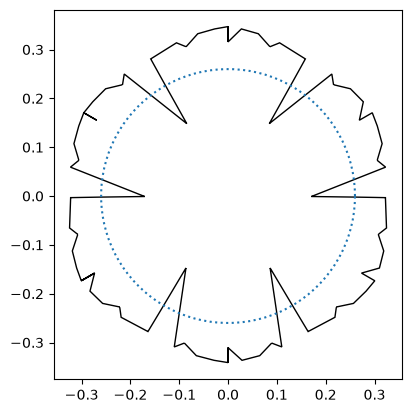

In [24]:
plt.fill(*sorted_yield_surface_points(100*sigs),fill=False,linestyle='solid')
#plt.plot(*sorted_yield_surface_points(100*sigs),'o')
alpha = np.linspace(0,2.*np.pi,100)
R = 0.26
plt.plot(R*np.cos(alpha),R*np.sin(alpha),linestyle='dotted')
plt.gca().set_aspect('equal')
plt.show()

In [25]:
v1c, v2c = 2*(np.sqrt(2.)-1), 2.0
v1, v2 = v1c + 1e-3/(np.sqrt(2)-1), v2c
model = mct.f12gammadot_tensorial_model (v1, v2, gammadot=0., gammac=0.1,
                                         use_hhat=True, nu=1.0)
kappas_lc, sigs_lc = gen_yield_surface(model, s_family, lc=True)

0it [00:00, ?it/s]

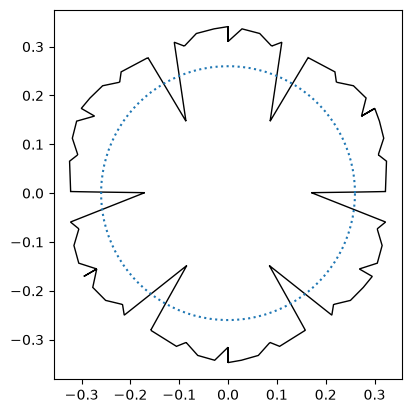

In [26]:
plt.fill(*sorted_yield_surface_points(100*sigs_lc),fill=False,linestyle='solid')
#plt.plot(*sorted_yield_surface_points(100*sigs),'o')
alpha = np.linspace(0,2.*np.pi,100)
R = 0.26
plt.plot(R*np.cos(alpha),R*np.sin(alpha),linestyle='dotted')
plt.gca().set_aspect('equal')
plt.show()